# Prueba de hipótesis: media y proporción con errores tipo I y tipo II

Desarrollo de los ejercicios de prueba de hipótesis para una sola población: pruebas de la media de
una distribución normal con varianza conocida y de una proporción poblacional. Se formulan las
hipótesis, se define el estadístico de prueba y su distribución bajo la nula, se expresa la regla de
decisión en escala estandarizada y en escala de medición, se calcula el valor p y se cuantifican los
errores tipo I y tipo II junto con la potencia. Los resultados se contrastan por simulación Monte
Carlo con semilla fija y, en el caso de las proporciones, contra la binomial exacta.

## Marco teórico

### Prueba de hipótesis

La prueba de hipótesis es un procedimiento de decisión sobre un parámetro poblacional a partir de una
muestra. Se plantean dos hipótesis mutuamente excluyentes:

- $H_0$ (hipótesis nula): la hipótesis de trabajo, se asume verdadera y es la que se busca rechazar
  con la evidencia de la muestra. Es el estado de referencia: el proceso sin cambios, el valor
  publicado, la alegación que hay que poner a prueba.
- $H_1$ (hipótesis alternativa): lo que se quiere demostrar, la afirmación con contenido práctico.

La lógica es por absurdo: se asume $H_0$ y se evalúa qué tan inverosímil sería observar la muestra
obtenida si $H_0$ fuera cierta. Si la evidencia resulta demasiado improbable bajo $H_0$, se rechaza.
La muestra nunca prueba $H_0$: solo admite rechazarlo o no rechazarlo. Decir que $H_0$ "se aceptó"
porque no se rechazó es un error de interpretación: no rechazar significa que no hay evidencia
suficiente en contra, no que la hipótesis sea verdadera.

### Estadístico de prueba

Sea $T = T(X_1, \dots, X_n)$ un estadístico cuya distribución se conoce bajo $H_0$. Para la media de
una normal con $\sigma$ conocida, el estadístico de prueba es

$$Z = \frac{\bar X - \mu_0}{\sigma/\sqrt{n}}$$

Bajo $H_0$ (con $\mu = \mu_0$) se tiene $Z \sim N(0,1)$: es el mismo pivote de la estimación por
intervalos, usado ahora para decidir en vez de para acotar. Bajo $H_1$, con $\mu = \mu_1$, la
distribución deja de estar centrada en cero:

$$Z \ \dot\sim \ N\!\left(\frac{\mu_1 - \mu_0}{\sigma/\sqrt{n}}, \ 1\right)$$

El corrimiento $(\mu_1 - \mu_0)/(\sigma/\sqrt{n})$ es el tamaño del efecto medido en errores estándar.
Toda la potencia de la prueba proviene de ese corrimiento: si es pequeño, las dos distribuciones se
superponen y ningún umbral permite distinguirlas bien.

### Regla de decisión y región de rechazo

Se fija $\alpha$, la probabilidad de rechazar $H_0$ cuando es verdadera, y se define la región de
rechazo como el conjunto de valores del estadístico para los que se rechaza. En escala
estandarizada, para una prueba unilateral superior:

$$\text{rechazar } H_0 \ \text{ si } \ z > z_{\alpha}$$

y para una prueba bilateral: rechazar si $|z| > z_{\alpha/2}$. La regla equivalente en la escala de
medición se obtiene despejando $\bar x$: unilateral superior, rechazar si
$\bar x > \mu_0 + z_{\alpha}\,\sigma/\sqrt{n}$; bilateral, si $|\bar x - \mu_0| >
z_{\alpha/2}\,\sigma/\sqrt{n}$. Ambas formas son la misma frontera en unidades distintas: la escala
estandarizada sirve para comparar pruebas entre sí, la de medición sirve para aplicarla en la planta
sin calcular el estadístico.

Cuando la alternativa es unilateral, el caso que se usa para calibrar la regla es el frontera
($\mu = \mu_0$): es el menos favorable a $H_1$ y el que maximiza la probabilidad de rechazo bajo
$H_0$. Si la regla respeta $\alpha$ ahí, lo respeta para cualquier valor de $H_0$.

### Errores tipo I y tipo II

Toda decisión bajo incertidumbre puede equivocarse. Los dos errores se cruzan con la verdad de $H_0$:

| | $H_0$ verdadera | $H_0$ falsa |
|---|---|---|
| **Rechazar $H_0$** | Error tipo I ($\alpha$) | Decisión correcta |
| **No rechazar $H_0$** | Decisión correcta | Error tipo II ($\beta$) |

$$\alpha = P(\text{rechazar } H_0 \mid H_0 \text{ verdadera}), \qquad \beta = P(\text{no rechazar } H_0 \mid H_1 \text{ verdadera})$$

El error tipo I es una falsa alarma: detener un proceso que estaba bajo control, rechazar una
máquina que rinde lo prometido. El error tipo II es dejar pasar un defecto: continuar un proceso
desajustado, no detectar una proporción fuera de especificación. Con el tamaño de muestra fijo,
$\alpha$ y $\beta$ son inversos: cualquier regla que baje uno sube el otro. Por eso se fija $\alpha$
por convención (0.05, 0.01, o 0.06 cuando el costo del error lo justifica) y recién entonces se
calcula $\beta$.

### Potencia de la prueba

$$\text{potencia} = 1 - \beta = P(\text{rechazar } H_0 \mid H_1 \text{ verdadera})$$

La potencia mide la capacidad de la prueba para detectar un desvío real. Para la media con $\sigma$
conocida y prueba unilateral superior, el umbral en la escala de medición es
$c = \mu_0 + z_{\alpha}\,\sigma/\sqrt{n}$ y, suponiendo $\mu = \mu_1$ bajo $H_1$:

$$\beta(\mu_1) = P(\bar X \le c \mid \mu_1) = \Phi\!\left(\frac{c - \mu_1}{\sigma/\sqrt{n}}\right)$$

Tres factores gobiernan la potencia: el tamaño del efecto $|\mu_1 - \mu_0|$, el nivel $\alpha$ y el
tamaño de muestra $n$ a través del error estándar. La curva de potencia $1 - \beta(\mu)$ crece desde
$\alpha$ en $\mu = \mu_0$ hasta $1$ cuando el efecto se aleja. Un $\beta$ alto cerca de $H_0$ no es un
defecto de la prueba: es la consecuencia de exigir pocas falsas alarmas con muestras pequeñas.

### Valor p

El valor p es la probabilidad, calculada bajo $H_0$, de observar un estadístico al menos tan extremo
que el obtenido:

$$p = P(T \ge T_{\text{obs}} \mid H_0) \quad \text{(cola superior)}, \qquad p = P(|T| \ge |T_{\text{obs}}| \mid H_0) \quad \text{(bilateral)}$$

La regla en términos del valor p es equivalente a la región de rechazo: rechazar $H_0$ si
$p < \alpha$. El valor p resume la evidencia de la muestra contra $H_0$ sin depender del nivel
elegido. Dos precisiones de interpretación: no es la probabilidad de que $H_0$ sea verdadera (eso
exigiría una distribución previa sobre el parámetro), y su magnitud no mide el tamaño del efecto:
con muestras grandes, desviaciones prácticas diminutas producen valores p minúsculos.

### Prueba de hipótesis para una proporción

Sea $X$ el número de éxitos en $n$ ensayos independientes con probabilidad $\pi$. Bajo
$H_0: \pi = \pi_0$, la proporción muestral tiene $E[\hat p] = \pi_0$ y
$\operatorname{Var}(\hat p) = \pi_0(1-\pi_0)/n$, de donde

$$Z = \frac{\hat p - \pi_0}{\sqrt{\pi_0(1-\pi_0)/n}} \ \dot\sim \ N(0,1) \ \text{ bajo } H_0$$

Detalle que distingue esta prueba de la estimación por intervalos: el error estándar se calcula con
$\pi_0$, el valor que impone la hipótesis nula, y no con $\hat p$. La distribución del estadístico se
deriva bajo $H_0$, y ahí $\pi$ tiene el valor conocido que fija la hipótesis. Condición de validez de
la aproximación normal: $n\pi_0 \ge 5$ y $n(1-\pi_0) \ge 5$.

Como $\hat p$ es discreta (múltiplos de $1/n$), la regla expresada en la escala de la proporción se
traduce en un umbral entero para $X$, y el tamaño real de la prueba puede diferir del $\alpha$
nominal que asigna la aproximación normal. La discrepancia crece cerca de los extremos de la
distribución binomial; se cuantifica en la sección 4.

### Dualidad con el intervalo de confianza

Rechazar $H_0: \mu = \mu_0$ con una prueba bilateral al nivel $\alpha$ es equivalente a que $\mu_0$
caiga fuera del intervalo de confianza $(1-\alpha)$ para $\mu$. Prueba e intervalo son la misma
información presentada de dos formas: la prueba responde "¿es este valor compatible con la muestra?",
el intervalo responde "¿qué valores son compatibles?". La regla de una prueba unilateral corresponde
al límite de un intervalo de una sola cola.

### Cuantiles de referencia

Los cuantiles se eligen según la cola que tenga la hipótesis alternativa; la clave es la probabilidad
de la cola de rechazo, no el nivel declarado de la prueba:

| Uso | Cola de rechazo $q$ | $z_q$ |
|---|---|---|
| Unilateral, $\alpha = 0.05$ | 0.050 | 1.644854 |
| Unilateral, $\alpha = 0.06$ | 0.060 | 1.554774 |
| Bilateral, $\alpha = 0.05$ | 0.025 | 1.959964 |
| Unilateral o bilateral, $\alpha = 0.01$ | 0.010 | 2.326348 |


In [1]:

import math

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

AZUL = "#1f4e79"
GRIS = "#808080"
VERDE = "#2e7d32"
ROJO = "#b03a2e"

# cuantiles de la normal estandar: clave = probabilidad de la cola superior P(Z > z)
Z = {0.005: 2.575829, 0.01: 2.326348, 0.025: 1.959964, 0.05: 1.644854, 0.06: 1.554774}


def cola_normal(z):
    """P(Z > z) para Z ~ N(0,1), via la funcion error complementaria."""
    return 0.5 * math.erfc(z / math.sqrt(2))


def Phi(z):
    """P(Z <= z) para Z ~ N(0,1)."""
    return 0.5 * (1.0 + math.erf(z / math.sqrt(2)))


Phi_vec = np.vectorize(Phi)


def binom_cdf(x, n_, p_):
    """P(X <= x) para X ~ Binomial(n_, p_), suma exacta de la masa."""
    return sum(math.comb(n_, k) * p_**k * (1 - p_)**(n_ - k) for k in range(int(x) + 1))


print("numpy", np.__version__, "| matplotlib", mpl.__version__)
print()
print(f"{'cola q':>8}{'z_q':>12}{'P(Z > z_q)':>14}{'|diff|':>12}")
print("-" * 46)
for q in sorted(Z):
    z_q = Z[q]
    print(f"{q:>8.3f}{z_q:>12.6f}{cola_normal(z_q):>14.6f}{abs(cola_normal(z_q) - q):>12.1e}")


numpy 2.4.4 | matplotlib 3.10.9

  cola q         z_q    P(Z > z_q)      |diff|
----------------------------------------------
   0.005    2.575829      0.005000     4.4e-09
   0.010    2.326348      0.010000     3.4e-09
   0.025    1.959964      0.025000     9.0e-10
   0.050    1.644854      0.050000     3.8e-08
   0.060    1.554774      0.060000     4.8e-08


## 1. Producción de una máquina: prueba unilateral de la media

Un proceso industrial da una producción media de 100 unidades por hora con desviación estándar de 8
unidades. Se ofrece una máquina más costosa que resultará más lucrativa si su producción media
supera las 150 unidades por hora. En una demostración de $n = 35$ horas de funcionamiento, la
máquina produjo una media de $\bar x = 160$ unidades por hora. Se usa un nivel de significación
$\alpha = 0.05$ y se toma $\sigma = 8$ unidades conocida y constante. La media de 100 unidades del
proceso actual es contexto: lo que decide la compra es superar 150, de modo que contra ese valor se
prueba. Con $n = 35$ y $\sigma$ conocida, el teorema del límite central habilita el pivote normal
aunque la forma de la población se desconozca.

### a) Hipótesis

$$H_0: \mu \le 150 \qquad \text{vs} \qquad H_1: \mu > 150$$

$H_0$ reúne las situaciones en las que la máquina no justifica la inversión; $H_1$ es la condición de
rentabilidad que hay que demostrar. Para calibrar la regla se usa el caso frontera $\mu = 150$, el
menos favorable a $H_1$. La evidencia solo puede apoyar $H_1$ con una media observada por encima de
150, por eso la prueba es unilateral derecha.

### b) Estadístico de prueba y distribución muestral

$$Z = \frac{\bar X - 150}{\sigma/\sqrt{n}} = \frac{\bar X - 150}{8/\sqrt{35}}$$

Bajo $H_0$, $\bar X \sim N(150,\ 64/35)$ con error estándar

$$\frac{\sigma}{\sqrt{n}} = \frac{8}{5.916080} = 1.352247 \text{ unidades/hora}$$

y por lo tanto $Z \sim N(0,1)$. Bajo $\mu = 160$, la distribución de $Z$ se centra en
$(160-150)/1.352247 = 7.3951$: la alternativa está desplazada casi siete errores estándar, un
anticipo del resultado.

### c) Regla de decisión en escala estandarizada

$$\text{rechazar } H_0 \ \text{ si } \ z > z_{0.05} = 1.644854$$

En la escala de medición la misma frontera es $\bar x > 150 + 1.644854 \times 1.352247 = 152.2242$
unidades por hora.

### d) Decisión

$$z = \frac{160 - 150}{1.352247} = 7.3951 \ > \ 1.644854$$

Se rechaza $H_0$: la muestra es compatible con una producción media superior a 150 unidades por
hora y, según el criterio del inciso a), sí conviene comprar la máquina.

### e) Valor p

$$p = P(Z > 7.3951) = 7.07 \times 10^{-14}$$

Es la probabilidad de obtener una media muestral de 160 o mayor si la producción media real fuera
exactamente 150. Prácticamente cero. La distancia entre el estadístico observado y el crítico
(7.3951 contra 1.6449) muestra que la decisión no es un efecto del nivel de significación elegido:
cualquier umbral razonable rechazaría la misma hipótesis.

In [2]:
mu0, sigma, n_horas = 150.0, 8.0, 35
xbar_obs = 160.0
alpha = 0.05

se = sigma / math.sqrt(n_horas)
z = (xbar_obs - mu0) / se
z_crit = Z[alpha]
umbral_xbar = mu0 + z_crit * se
p_valor = cola_normal(z)

print(f"H0: mu <= {mu0:.0f} vs H1: mu > {mu0:.0f}   |   alpha = {alpha}")
print(f"n = {n_horas} horas, xbar = {xbar_obs:.0f} u/h, sigma = {sigma:.0f} u/h")
print(f"error estandar: {sigma:.0f}/sqrt({n_horas}) = {sigma:.0f}/{math.sqrt(n_horas):.6f} = {se:.6f} u/h")
print(f"bajo H0: Xbar ~ N({mu0:.0f}, {sigma**2 / n_horas:.4f}), Z ~ N(0,1)")
print()
print(f"regla estandarizada: rechazar si z > {z_crit:.6f}")
print(f"escala de medicion: xbar > {mu0:.0f} + {z_crit:.6f} x {se:.6f} = {umbral_xbar:.4f} u/h")
print()
print(f"z observado = ({xbar_obs:.0f} - {mu0:.0f})/{se:.6f} = {z:.4f}")
print(f"decision: {'rechazar H0' if z > z_crit else 'no rechazar H0'}"
      f"   |   z = {z:.4f} vs {z_crit:.6f}")
print(f"valor p = P(Z > {z:.4f}) = {p_valor:.4e}")
print()
print(f"distribucion alternativa si mu = 160: Z ~ N({(xbar_obs - mu0) / se:.4f}, 1)")


H0: mu <= 150 vs H1: mu > 150   |   alpha = 0.05
n = 35 horas, xbar = 160 u/h, sigma = 8 u/h
error estandar: 8/sqrt(35) = 8/5.916080 = 1.352247 u/h
bajo H0: Xbar ~ N(150, 1.8286), Z ~ N(0,1)

regla estandarizada: rechazar si z > 1.644854
escala de medicion: xbar > 150 + 1.644854 x 1.352247 = 152.2242 u/h

z observado = (160 - 150)/1.352247 = 7.3951
decision: rechazar H0   |   z = 7.3951 vs 1.644854
valor p = P(Z > 7.3951) = 7.0651e-14

distribucion alternativa si mu = 160: Z ~ N(7.3951, 1)


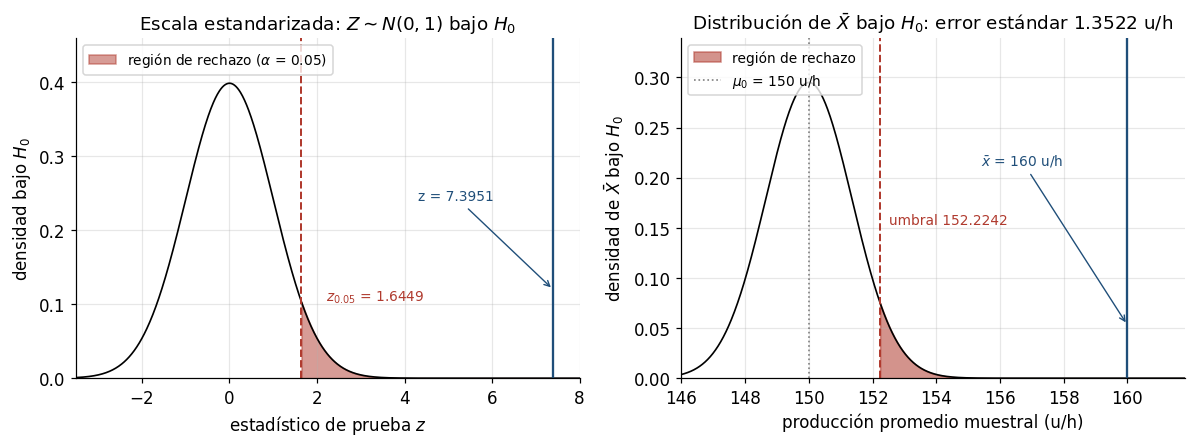

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

# panel izquierdo: escala estandarizada
malla = np.linspace(-3.5, 8.0, 1000)
dens = np.exp(-0.5 * malla**2) / math.sqrt(2 * math.pi)

axs[0].plot(malla, dens, color="black", linewidth=1.1)
axs[0].fill_between(malla, 0, dens, where=malla >= z_crit, color=ROJO, alpha=0.5,
                    label=r"región de rechazo ($\alpha$ = 0.05)")
axs[0].axvline(z_crit, color=ROJO, linewidth=1.3, linestyle="--")
axs[0].text(z_crit + 0.55, 0.105, r"$z_{0.05}$ = 1.6449", color=ROJO, fontsize=9)
axs[0].axvline(z, color=AZUL, linewidth=1.5)
axs[0].annotate(f"z = {z:.4f}", xy=(z, 0.12), xytext=(4.3, 0.24), color=AZUL, fontsize=9,
                arrowprops=dict(arrowstyle="->", linewidth=0.9, color=AZUL))
axs[0].set_xlim(-3.5, 8)
axs[0].set_ylim(0, 0.46)
axs[0].set_xlabel(r"estadístico de prueba $z$")
axs[0].set_ylabel("densidad bajo $H_0$")
axs[0].set_title(r"Escala estandarizada: $Z \sim N(0,1)$ bajo $H_0$")
axs[0].legend(fontsize=9, loc="upper left")

# panel derecho: escala de medición
malla2 = np.linspace(145.5, 162, 1000)
dens2 = np.exp(-0.5 * ((malla2 - mu0) / se) ** 2) / (se * math.sqrt(2 * math.pi))
altura = dens2.max()

axs[1].plot(malla2, dens2, color="black", linewidth=1.1)
axs[1].fill_between(malla2, 0, dens2, where=malla2 >= umbral_xbar, color=ROJO, alpha=0.55,
                    label="región de rechazo")
axs[1].axvline(umbral_xbar, color=ROJO, linewidth=1.3, linestyle="--")
axs[1].text(umbral_xbar + 0.3, altura * 0.52, f"umbral {umbral_xbar:.4f}", color=ROJO, fontsize=9)
axs[1].axvline(xbar_obs, color=AZUL, linewidth=1.5)
axs[1].annotate(r"$\bar{x}$ = 160 u/h", xy=(xbar_obs, altura * 0.18),
                xytext=(155.4, altura * 0.72), color=AZUL, fontsize=9,
                arrowprops=dict(arrowstyle="->", linewidth=0.9, color=AZUL))
axs[1].axvline(mu0, color=GRIS, linewidth=1.1, linestyle=":", label=r"$\mu_0$ = 150 u/h")
axs[1].set_xlim(146, 161.8)
axs[1].set_ylim(0, altura * 1.15)
axs[1].set_xlabel("producción promedio muestral (u/h)")
axs[1].set_ylabel("densidad de $\\bar{X}$ bajo $H_0$")
axs[1].set_title(r"Distribución de $\bar{X}$ bajo $H_0$: error estándar 1.3522 u/h")
axs[1].legend(fontsize=9, loc="upper left")

plt.tight_layout()
plt.show()


## 2. Proceso de llenado: regla de decisión, error tipo II y potencia

La cantidad promedio que se coloca en un recipiente se fijó en $\mu_0 = 20$ gramos y la cantidad que
se vacía en cada recipiente se distribuye normalmente con desviación estándar $\sigma = 5$ gramos. El
gerente de producción sospecha que el proceso se ha desajustado, colocando una cantidad superior. Se
toman muestras aleatorias de $n = 30$ recipientes y se pesa el contenido de cada uno. Nivel de
significación $\alpha = 0.05$.

### a) Hipótesis

$$H_0: \mu = 20 \qquad \text{vs} \qquad H_1: \mu > 20$$

La sospecha es de exceso de carga, de modo que la alternativa es unilateral derecha: el interés está
en detectar colocaciones superiores, no en cualquier desvío.

### b) Regla de decisión en la escala de medición

Bajo $H_0$, $\bar X \sim N(20,\ 25/30)$ con error estándar

$$\frac{\sigma}{\sqrt{n}} = \frac{5}{\sqrt{30}} = 0.912871 \text{ gramos}$$

La frontera en escala estandarizada es $z > z_{0.05} = 1.644854$; despejando $\bar x$:

$$\bar x > 20 + 1.644854 \times 0.912871 = 21.5015 \text{ gramos}$$

Con $n = 30$, cualquier media muestral mayor a 21.5015 gramos lleva a declarar el proceso fuera de
control.

### c) Decisión con la muestra

Con $\bar x = 22.30$ gramos:

$$z = \frac{22.30 - 20}{0.912871} = 2.5195 \ > \ 1.644854, \qquad p = P(Z > 2.5195) = 0.005876$$

Se rechaza $H_0$: la sospecha del gerente está justificada. La media observada queda 0.80 gramos por
encima del umbral, casi tres errores estándar por encima del valor fijado.

### d) Error tipo II y potencia si la media verdadera es 22 gramos

Si $\mu = 22$, el umbral de decisión se estandariza bajo la nueva media:

$$\beta = P(\bar X \le 21.5015 \mid \mu = 22) = \Phi\!\left(\frac{21.5015 - 22}{0.912871}\right) = \Phi(-0.5460) = 0.2925$$

$$\text{potencia} = 1 - \beta = 0.7075$$

Si el proceso realmente estuviera cargando 22 gramos, esta prueba lo detectaría el 70.7% de las veces
y dejaría pasar el desajuste el 29.3% de las veces. El efecto de 2 gramos equivale a 2.19 errores
estándar: suficiente para que la prueba sea útil, insuficiente para que sea contundente con 30
observaciones.

### e) Error tipo I asumido con umbral 21.83 gramos

Si se juzgara fuera de control cuando $\bar x > 21.83$:

$$\alpha = P(\bar X > 21.83 \mid \mu = 20) = P\!\left(Z > \frac{21.83 - 20}{0.912871}\right) = P(Z > 2.0047) = 0.0225$$

El umbral más exigente reduce el error tipo I a 0.0225, menos de la mitad del 0.05 fijado. Es el
trade-off directo: al subir el umbral se encarece la falsa alarma y al mismo tiempo se agranda el
error tipo II, que con $\mu = 22$ pasa de 0.2925 a $\Phi((21.83 - 22)/0.912871) = \Phi(-0.1862) =
0.4261$.

In [4]:
mu0, sigma, n_rec = 20.0, 5.0, 30
alpha = 0.05
xbar_obs = 22.30
mu1 = 22.0

se = sigma / math.sqrt(n_rec)
z_crit = Z[alpha]
umbral = mu0 + z_crit * se

print(f"H0: mu = {mu0:.0f} vs H1: mu > {mu0:.0f}   |   alpha = {alpha}, n = {n_rec}, sigma = {sigma:.0f} g")
print(f"bajo H0: Xbar ~ N({mu0:.0f}, {sigma**2 / n_rec:.4f}), error estandar = {sigma:.0f}/sqrt({n_rec}) = {se:.6f} g")
print(f"regla estandarizada: z > {z_crit:.6f}")
print(f"regla en escala de medicion: xbar > {mu0:.0f} + {z_crit:.6f} x {se:.6f} = {umbral:.4f} g")
print()

z = (xbar_obs - mu0) / se
p_valor = cola_normal(z)
print(f"c) xbar = {xbar_obs:.2f} g -> z = ({xbar_obs:.2f} - {mu0:.0f})/{se:.6f} = {z:.4f}")
print(f"   {'rechazar H0' if z > z_crit else 'no rechazar H0'}: z = {z:.4f} vs {z_crit:.6f},"
      f"   p = {p_valor:.6f}")

z_beta = (umbral - mu1) / se
beta = Phi(z_beta)
print()
print(f"d) si mu = {mu1:.0f}: beta = P(Xbar <= {umbral:.4f}) = Phi(({umbral:.4f} - {mu1:.0f})/{se:.6f})")
print(f"   = Phi({z_beta:.4f}) = {beta:.6f} -> potencia = {1 - beta:.6f}")
print(f"   efecto en errores estandar: ({mu1:.0f} - {mu0:.0f})/{se:.6f} = {(mu1 - mu0) / se:.4f}")

umbral_alt = 21.83
z_alt = (umbral_alt - mu0) / se
alpha_alt = cola_normal(z_alt)
beta_alt = Phi((umbral_alt - mu1) / se)
print()
print(f"e) umbral {umbral_alt} g: z = ({umbral_alt} - {mu0:.0f})/{se:.6f} = {z_alt:.4f}")
print(f"   alpha asumido = P(Z > {z_alt:.4f}) = {alpha_alt:.6f}   (vs 0.05 del inciso b)")
print(f"   con mu = {mu1:.0f}: beta = {beta_alt:.6f} -> potencia = {1 - beta_alt:.6f}")


H0: mu = 20 vs H1: mu > 20   |   alpha = 0.05, n = 30, sigma = 5 g
bajo H0: Xbar ~ N(20, 0.8333), error estandar = 5/sqrt(30) = 0.912871 g
regla estandarizada: z > 1.644854
regla en escala de medicion: xbar > 20 + 1.644854 x 0.912871 = 21.5015 g

c) xbar = 22.30 g -> z = (22.30 - 20)/0.912871 = 2.5195
   rechazar H0: z = 2.5195 vs 1.644854,   p = 0.005876

d) si mu = 22: beta = P(Xbar <= 21.5015) = Phi((21.5015 - 22)/0.912871)
   = Phi(-0.5460) = 0.292521 -> potencia = 0.707479
   efecto en errores estandar: (22 - 20)/0.912871 = 2.1909

e) umbral 21.83 g: z = (21.83 - 20)/0.912871 = 2.0047
   alpha asumido = P(Z > 2.0047) = 0.022499   (vs 0.05 del inciso b)
   con mu = 22: beta = 0.426134 -> potencia = 0.573866


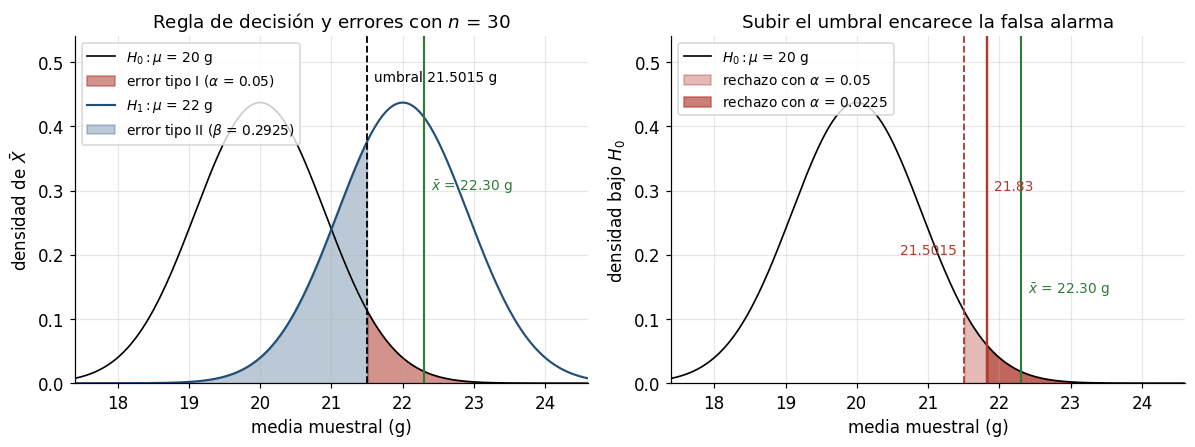

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

# panel izquierdo: distribuciones bajo H0 y H1 con los dos errores
malla = np.linspace(17.4, 24.6, 1100)
dens0 = np.exp(-0.5 * ((malla - mu0) / se) ** 2) / (se * math.sqrt(2 * math.pi))
dens1 = np.exp(-0.5 * ((malla - mu1) / se) ** 2) / (se * math.sqrt(2 * math.pi))

axs[0].plot(malla, dens0, color="black", linewidth=1.1, label=r"$H_0: \mu$ = 20 g")
axs[0].fill_between(malla, 0, dens0, where=malla >= umbral, color=ROJO, alpha=0.55,
                    label=r"error tipo I ($\alpha$ = 0.05)")
axs[0].plot(malla, dens1, color=AZUL, linewidth=1.4, label=r"$H_1: \mu$ = 22 g")
axs[0].fill_between(malla, 0, dens1, where=malla <= umbral, color=AZUL, alpha=0.3,
                    label=r"error tipo II ($\beta$ = 0.2925)")
axs[0].axvline(umbral, color="black", linewidth=1.2, linestyle="--")
axs[0].text(umbral + 0.1, 0.47, f"umbral {umbral:.4f} g", fontsize=9)
axs[0].axvline(xbar_obs, color=VERDE, linewidth=1.4)
axs[0].text(xbar_obs + 0.1, 0.30, r"$\bar{x}$ = 22.30 g", fontsize=9, color=VERDE)
axs[0].set_xlim(17.4, 24.6)
axs[0].set_ylim(0, 0.54)
axs[0].set_xlabel("media muestral (g)")
axs[0].set_ylabel("densidad de $\\bar{X}$")
axs[0].set_title("Regla de decisión y errores con $n$ = 30")
axs[0].legend(fontsize=9, loc="upper left")

# panel derecho: umbral del inciso b) contra el umbral más exigente del inciso e)
umbral_alt = 21.83
malla2 = np.linspace(17.4, 24.6, 1100)
dens0 = np.exp(-0.5 * ((malla2 - mu0) / se) ** 2) / (se * math.sqrt(2 * math.pi))

axs[1].plot(malla2, dens0, color="black", linewidth=1.1, label=r"$H_0: \mu$ = 20 g")
axs[1].fill_between(malla2, 0, dens0, where=malla2 >= umbral, color=ROJO, alpha=0.35,
                    label=r"rechazo con $\alpha$ = 0.05")
axs[1].fill_between(malla2, 0, dens0, where=malla2 >= umbral_alt, color=ROJO, alpha=0.65,
                    label=r"rechazo con $\alpha$ = 0.0225")
axs[1].axvline(umbral, color=ROJO, linewidth=1.2, linestyle="--")
axs[1].text(umbral - 0.1, 0.20, f"{umbral:.4f}", fontsize=9, color=ROJO, ha="right")
axs[1].axvline(umbral_alt, color=ROJO, linewidth=1.6)
axs[1].text(umbral_alt + 0.1, 0.30, f"{umbral_alt:.2f}", fontsize=9, color=ROJO)
axs[1].axvline(xbar_obs, color=VERDE, linewidth=1.4)
axs[1].text(xbar_obs + 0.1, 0.14, r"$\bar{x}$ = 22.30 g", fontsize=9, color=VERDE)
axs[1].set_xlim(17.4, 24.6)
axs[1].set_ylim(0, 0.54)
axs[1].set_xlabel("media muestral (g)")
axs[1].set_ylabel("densidad bajo $H_0$")
axs[1].set_title("Subir el umbral encarece la falsa alarma")
axs[1].legend(fontsize=9, loc="upper left")

plt.tight_layout()
plt.show()


La simulación siguiente repite el procedimiento completo —muestreo, estadístico, comparación con
el umbral— bajo $H_0$ y bajo $H_1$, y cuenta las veces que se comete cada error. Es la comprobación
directa de que la regla construida produce el $\alpha$ fijado y el $\beta$ calculados, con el único
ruido del muestreo finito.

In [6]:
rng = np.random.default_rng(11)
ensayos = 100_000

bajo_h0 = rng.normal(mu0, se, size=ensayos)
bajo_h1 = rng.normal(mu1, se, size=ensayos)

alpha_emp = (bajo_h0 > umbral).mean()
beta_emp = (bajo_h1 <= umbral).mean()

err_alpha = math.sqrt(alpha * (1 - alpha) / ensayos)
err_beta = math.sqrt(beta * (1 - beta) / ensayos)

print(f"ensayos Monte Carlo: {ensayos:,} (semilla 11), umbral xbar > {umbral:.4f} g")
print()
print(f"{'cantidad':>10}{'calculado':>12}{'simulado':>12}{'error muestral':>18}")
print("-" * 54)
print(f"{'alpha':>10}{alpha:>12.4f}{alpha_emp:>12.4f}{err_alpha:>18.4f}")
print(f"{'beta':>10}{beta:>12.4f}{beta_emp:>12.4f}{err_beta:>18.4f}")
print(f"{'potencia':>10}{1 - beta:>12.4f}{1 - beta_emp:>12.4f}{err_beta:>18.4f}")
print()
print(f"desviacion |simulado - calculado|: alpha {abs(alpha_emp - alpha):.4f}"
      f"   beta {abs(beta_emp - beta):.4f}")
print(f"limite de 3 sigmas: alpha {3 * err_alpha:.4f}   beta {3 * err_beta:.4f}")


ensayos Monte Carlo: 100,000 (semilla 11), umbral xbar > 21.5015 g

  cantidad   calculado    simulado    error muestral
------------------------------------------------------
     alpha      0.0500      0.0493            0.0007
      beta      0.2925      0.2945            0.0014
  potencia      0.7075      0.7055            0.0014

desviacion |simulado - calculado|: alpha 0.0007   beta 0.0019
limite de 3 sigmas: alpha 0.0021   beta 0.0043


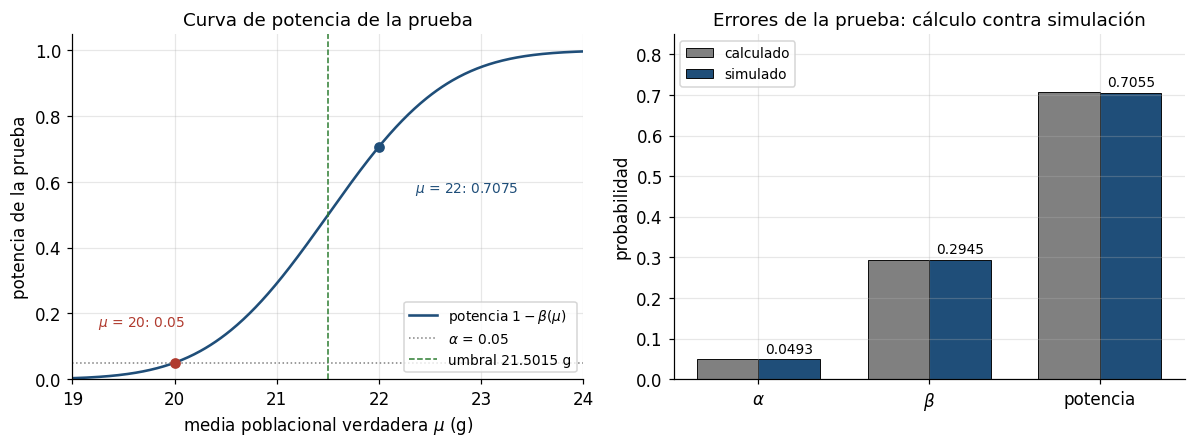

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

mu_grilla = np.linspace(19, 24, 500)
potencia = Phi_vec((mu_grilla - umbral) / se)

axs[0].plot(mu_grilla, potencia, color=AZUL, linewidth=1.7, label=r"potencia $1-\beta(\mu)$")
axs[0].axhline(alpha, color=GRIS, linewidth=1.0, linestyle=":", label=r"$\alpha$ = 0.05")
axs[0].axvline(umbral, color=VERDE, linewidth=1.0, linestyle="--",
               label=f"umbral {umbral:.4f} g")
for mu_p, color, dx, dy, texto in [(mu0, ROJO, -0.75, 0.11, r"$\mu$ = 20: 0.05"),
                                   (mu1, AZUL, 0.35, -0.14, r"$\mu$ = 22: 0.7075")]:
    pot = float(Phi((mu_p - umbral) / se))
    axs[0].plot(mu_p, pot, "o", color=color, zorder=5)
    axs[0].text(mu_p + dx, pot + dy, texto, fontsize=9, color=color)
axs[0].set_xlim(19, 24)
axs[0].set_ylim(0, 1.05)
axs[0].set_xlabel(r"media poblacional verdadera $\mu$ (g)")
axs[0].set_ylabel("potencia de la prueba")
axs[0].set_title("Curva de potencia de la prueba")
axs[0].legend(fontsize=9, loc="lower right")

categorias = [r"$\alpha$", r"$\beta$", "potencia"]
nominal = [alpha, beta, 1 - beta]
empirico = [alpha_emp, beta_emp, 1 - beta_emp]
pos = np.arange(3)

axs[1].bar(pos - 0.18, nominal, width=0.36, color=GRIS, edgecolor="black", linewidth=0.6,
           label="calculado")
axs[1].bar(pos + 0.18, empirico, width=0.36, color=AZUL, edgecolor="black", linewidth=0.6,
           label="simulado")
for x_pos, valor in zip(pos + 0.18, empirico):
    axs[1].text(x_pos, valor + 0.015, f"{valor:.4f}", ha="center", fontsize=9)
axs[1].set_xticks(pos, categorias)
axs[1].set_ylim(0, 0.85)
axs[1].set_ylabel("probabilidad")
axs[1].set_title("Errores de la prueba: cálculo contra simulación")
axs[1].legend(fontsize=9)

plt.tight_layout()
plt.show()


## 3. Pieza mecanizada: prueba bilateral con umbral de control

Una pieza fabricada tiene una dimensión crítica de $\mu_0 = 4.6$ cm que se distribuye normalmente
con desviación estándar $\sigma = 0.5$ cm. El proceso se considera bajo control si produce la pieza
con media 4.6 cm; si no, se detiene. Para comprobar el control se toman $n = 5$ piezas cada dos
horas y se usa $\alpha = 0.05$. La tolerancia es simétrica: tanto un exceso como un defecto de la
dimensión crítica implican desvío, por eso la prueba es bilateral.

### a) Hipótesis

$$H_0: \mu = 4.6 \qquad \text{vs} \qquad H_1: \mu \ne 4.6$$

### b) Valores para considerar el proceso bajo control

$$\frac{\sigma}{\sqrt{n}} = \frac{0.5}{\sqrt{5}} = 0.223607 \text{ cm}, \qquad z_{0.025} = 1.959964$$

$$\text{rechazar } H_0 \ \text{ si } \ |\bar x - 4.6| > 1.959964 \times 0.223607 = 0.438261$$

$$4.1617 \ \le \ \bar x \ \le \ 5.0383 \ \Longrightarrow \ \text{bajo control}$$

Fuera de ese rango el proceso se detiene: por debajo de 4.1617 la pieza sale subdimensionada, por
encima de 5.0383 sobredimensionada.

### c) Muestra de 4.35 y valor p

$$z = \frac{4.35 - 4.60}{0.223607} = -1.1180, \qquad |z| = 1.1180 < 1.959964$$

$$p = 2\,P(Z > 1.1180) = 2 \times 0.131776 = 0.263552$$

No se rechaza $H_0$: con $p = 0.2636$ muy por encima de $\alpha = 0.05$ no hay evidencia de desvío y
el proceso sigue en marcha. La conclusión es "no se detectó desvío", no "la media es 4.6": la
muestra es compatible con 4.6, pero también con cualquier valor que la prueba no rechaza.

### d) Error tipo II para distintas medias poblacionales

$$\beta(\mu) = P(4.1617 \le \bar X \le 5.0383 \mid \mu) = \Phi\!\left(\frac{5.0383 - \mu}{0.223607}\right) - \Phi\!\left(\frac{4.1617 - \mu}{0.223607}\right)$$

| $\mu$ (cm) | $z_1$ | $z_2$ | $\beta$ | potencia $1-\beta$ |
|---|---|---|---|---|
| 4.40 | -1.0655 | 2.8544 | 0.8545 | 0.1455 |
| 4.50 | -1.5128 | 2.4072 | 0.9268 | 0.0732 |
| 4.60 | -1.9600 | 1.9600 | 0.9500 | 0.0500 |
| 4.70 | -2.4072 | 1.5128 | 0.9268 | 0.0732 |
| 4.80 | -2.8544 | 1.0655 | 0.8545 | 0.1455 |

Con $H_0$ verdadera, $\beta = 1 - \alpha = 0.95$ exacto: la prueba rechaza solo el 5% de las veces
cuando no hay nada que rechazar. El error tipo II es máximo cerca de la hipótesis nula y baja al
alejarse, con la simetría propia de una prueba bilateral. Los valores muestran el costo de $n = 5$:
para un desvío de 0.1 cm la potencia es apenas 7.3%, y aun con 0.2 cm de desvío no llega al 15%. El
proceso puede estar descontrolado y este muestreo casi nunca lo detectaría; dimensionar la
inspección exige aumentar $n$ o aceptar el riesgo.

In [8]:
mu0, sigma, n_piezas = 4.6, 0.5, 5
alpha = 0.05

se = sigma / math.sqrt(n_piezas)
z_crit = Z[alpha / 2]
margen = z_crit * se
lim_inf, lim_sup = mu0 - margen, mu0 + margen

print(f"H0: mu = {mu0} vs H1: mu != {mu0}   |   alpha = {alpha} (bilateral),"
      f" n = {n_piezas}, sigma = {sigma} cm")
print(f"error estandar: {sigma}/sqrt({n_piezas}) = {se:.6f} cm, z_{{alpha/2}} = {z_crit:.6f}")
print(f"margen = {z_crit:.6f} x {se:.6f} = {margen:.6f} cm")
print(f"bajo control si {lim_inf:.4f} <= xbar <= {lim_sup:.4f}")
print()

xbar_obs = 4.35
z = (xbar_obs - mu0) / se
p_valor = 2 * cola_normal(abs(z))
print(f"c) xbar = {xbar_obs} -> z = ({xbar_obs} - {mu0})/{se:.6f} = {z:.4f}")
print(f"   |z| = {abs(z):.4f} vs {z_crit:.6f} -> {'rechazar' if abs(z) > z_crit else 'no rechazar'} H0")
print(f"   valor p bilateral = 2 x P(Z > {abs(z):.4f}) = 2 x {cola_normal(abs(z)):.6f} = {p_valor:.6f}")
print()

print("d) error tipo II:")
print(f"{'mu':>6}{'z1':>10}{'z2':>10}{'beta':>10}{'potencia':>10}")
print("-" * 46)
for mu in (4.40, 4.50, 4.60, 4.70, 4.80):
    z1 = (lim_inf - mu) / se
    z2 = (lim_sup - mu) / se
    beta = Phi(z2) - Phi(z1)
    print(f"{mu:>6.2f}{z1:>10.4f}{z2:>10.4f}{beta:>10.4f}{1 - beta:>10.4f}")


H0: mu = 4.6 vs H1: mu != 4.6   |   alpha = 0.05 (bilateral), n = 5, sigma = 0.5 cm
error estandar: 0.5/sqrt(5) = 0.223607 cm, z_{alpha/2} = 1.959964
margen = 1.959964 x 0.223607 = 0.438261 cm
bajo control si 4.1617 <= xbar <= 5.0383

c) xbar = 4.35 -> z = (4.35 - 4.6)/0.223607 = -1.1180
   |z| = 1.1180 vs 1.959964 -> no rechazar H0
   valor p bilateral = 2 x P(Z > 1.1180) = 2 x 0.131776 = 0.263552

d) error tipo II:
    mu        z1        z2      beta  potencia
----------------------------------------------
  4.40   -1.0655    2.8544    0.8545    0.1455
  4.50   -1.5128    2.4072    0.9268    0.0732
  4.60   -1.9600    1.9600    0.9500    0.0500
  4.70   -2.4072    1.5128    0.9268    0.0732
  4.80   -2.8544    1.0655    0.8545    0.1455


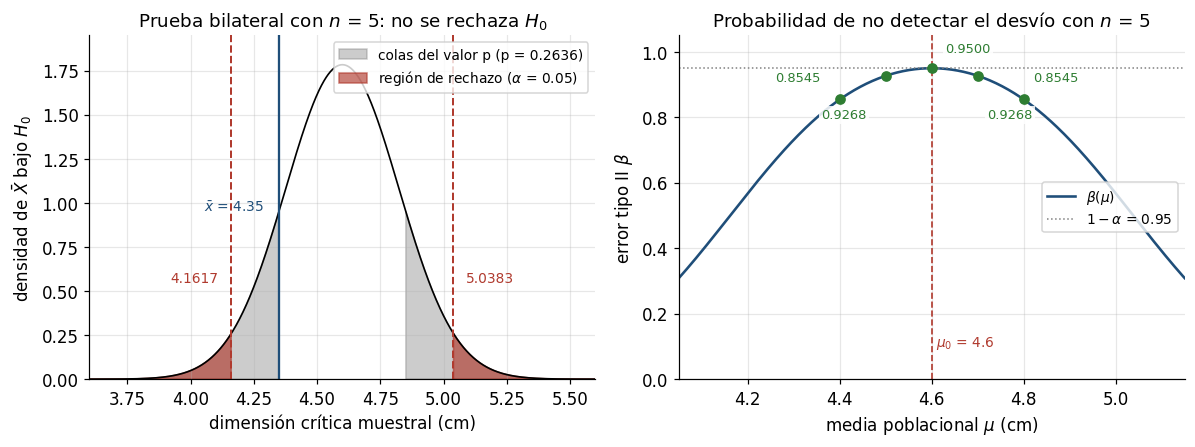

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

# panel izquierdo: regiones de rechazo y valor p
malla = np.linspace(3.6, 5.6, 1200)
dens = np.exp(-0.5 * ((malla - mu0) / se) ** 2) / (se * math.sqrt(2 * math.pi))
borde_p = mu0 - (xbar_obs - mu0)

axs[0].plot(malla, dens, color="black", linewidth=1.1)
axs[0].fill_between(malla, 0, dens, where=(malla <= xbar_obs) | (malla >= borde_p),
                    color=GRIS, alpha=0.4,
                    label=f"colas del valor p (p = {p_valor:.4f})")
axs[0].fill_between(malla, 0, dens, where=(malla <= lim_inf) | (malla >= lim_sup),
                    color=ROJO, alpha=0.65, label=r"región de rechazo ($\alpha$ = 0.05)")
axs[0].axvline(lim_inf, color=ROJO, linewidth=1.3, linestyle="--")
axs[0].axvline(lim_sup, color=ROJO, linewidth=1.3, linestyle="--")
axs[0].text(lim_inf - 0.05, 0.55, f"{lim_inf:.4f}", color=ROJO, fontsize=9, ha="right")
axs[0].text(lim_sup + 0.05, 0.55, f"{lim_sup:.4f}", color=ROJO, fontsize=9)
axs[0].axvline(xbar_obs, color=AZUL, linewidth=1.5)
axs[0].text(xbar_obs - 0.06, 0.95, r"$\bar{x}$ = 4.35", color=AZUL, fontsize=9, ha="right")
axs[0].set_xlim(3.6, 5.6)
axs[0].set_ylim(0, 1.95)
axs[0].set_xlabel("dimensión crítica muestral (cm)")
axs[0].set_ylabel("densidad de $\\bar{X}$ bajo $H_0$")
axs[0].set_title(r"Prueba bilateral con $n$ = 5: no se rechaza $H_0$")
axs[0].legend(fontsize=9, loc="upper right")

# panel derecho: curva del error tipo II
mu_grilla = np.linspace(4.05, 5.15, 500)
beta_grilla = Phi_vec((lim_sup - mu_grilla) / se) - Phi_vec((lim_inf - mu_grilla) / se)

axs[1].plot(mu_grilla, beta_grilla, color=AZUL, linewidth=1.7, label=r"$\beta(\mu)$")
axs[1].axhline(1 - alpha, color=GRIS, linewidth=1.0, linestyle=":",
               label=r"$1-\alpha$ = 0.95")
axs[1].axvline(mu0, color=ROJO, linewidth=1.1, linestyle="--")
axs[1].text(mu0 + 0.01, 0.10, r"$\mu_0$ = 4.6", color=ROJO, fontsize=9)
puntos = [(4.40, 0.854527, -0.14, 0.055), (4.50, 0.926790, -0.14, -0.13),
          (4.60, 0.950000, 0.03, 0.05), (4.70, 0.926790, 0.02, -0.13),
          (4.80, 0.854527, 0.02, 0.055)]
for mu_p, beta_p, dx, dy in puntos:
    axs[1].plot(mu_p, beta_p, "o", color=VERDE, markersize=6, zorder=5)
    axs[1].text(mu_p + dx, beta_p + dy, f"{beta_p:.4f}", fontsize=8.5, color=VERDE,
                bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=1.5))
axs[1].set_xlim(4.05, 5.15)
axs[1].set_ylim(0, 1.05)
axs[1].set_xlabel(r"media poblacional $\mu$ (cm)")
axs[1].set_ylabel(r"error tipo II $\beta$")
axs[1].set_title("Probabilidad de no detectar el desvío con $n$ = 5")
axs[1].legend(fontsize=9, loc="center right")

plt.tight_layout()
plt.show()


## 4. Puentes de acero intemperizado: prueba de una proporción

Expertos en corrosión sostienen que el acero intemperizado no debe usarse en puentes; las corporaciones
acereras aseguran que el 95% de los puentes de acero intemperizado en operación tienen buen
desempeño, sin daños graves por corrosión. Para probar esa aseveración, un equipo evaluó $n = 60$
puentes seleccionados al azar y encontró que $x = 54$ exhibían buen desempeño. Se pretende probar que
la verdadera proporción es menor a 0,95, con $\alpha = 0.05$.

### a) Hipótesis

$$H_0: \pi = 0.95 \qquad \text{vs} \qquad H_1: \pi < 0.95$$

$H_0$ es la afirmación de las corporaciones (la proporción publicada); $H_1$ es la posición de los
expertos, la que hay que demostrar con datos. La alternativa es unilateral izquierda: solo interesa
constatar que la proporción real queda por debajo de 0,95.

### b) Estadístico de prueba y distribución

$$Z = \frac{\hat p - \pi_0}{\sqrt{\pi_0(1-\pi_0)/n}} = \frac{\hat p - 0.95}{\sqrt{0.95 \times 0.05 / 60}}$$

Bajo $H_0$, $Z \sim N(0,1)$ y $\hat p \sim N(0.95,\ 0.028137^2)$, con error estándar

$$\sqrt{\frac{0.95 \times 0.05}{60}} = \sqrt{0.00079167} = 0.028137$$

El error estándar usa $\pi_0$ y no $\hat p$, porque la distribución del estadístico se deriva bajo la
hipótesis nula. Sobre la condición de aproximación: $n\pi_0 = 57 \ge 5$ se cumple, pero
$n(1-\pi_0) = 3 < 5$ no. La cola izquierda de la binomial con estos parámetros es más pesada de lo
que predice la normal, y la discrepancia se cuantifica más abajo; el ejercicio se resuelve con el
estadístico estandarizado pedido.

### c) Regla de decisión con $\alpha = 0.05$

$$\text{rechazar } H_0 \ \text{ si } \ z < -z_{0.05} = -1.644854$$

En la escala de la proporción:

$$\hat p < 0.95 - 1.644854 \times 0.028137 = 0.903719$$

Como $\hat p$ es un múltiplo de $1/60$, la regla equivale a exigir $X \le 54$ puentes en desempeño
aceptable.

### d) Decisión

$$\hat p = \frac{54}{60} = 0.90, \qquad z = \frac{0.90 - 0.95}{0.028137} = -1.7770 \ < \ -1.644854$$

Se rechaza $H_0$: la muestra da evidencia de que la proporción real de puentes con buen desempeño es
menor que 0,95, es decir que los expertos tienen razón en cuestionar la cifra publicada.

### e) Valor p

$$p = P(Z < -1.7770) = 0.037780 < 0.05$$

Es la probabilidad de observar una proporción muestral de 0,90 o menor si la proporción real fuera
0,95. Es inferior al nivel fijado, pero no por mucho: la evidencia es significativa al 5% y no lo
habría sido al 3%.

### f) Potencia para $\pi = 0.93$, $0.92$ y $0.91$

El umbral de decisión queda fijo en $\hat p < 0.903719$; bajo cada valor de $H_1$ se estandariza con
su propio error estándar $\sqrt{\pi(1-\pi)/60}$:

| $\pi$ | error estándar | $z$ | potencia (normal) | potencia (binomial exacta) |
|---|---|---|---|---|
| 0.93 | 0.032939 | -0.7978 | 0.2125 | 0.2420 |
| 0.92 | 0.035024 | -0.4648 | 0.3210 | 0.3474 |
| 0.91 | 0.036946 | -0.1700 | 0.4325 | 0.4571 |

Las potencias son bajas: incluso si la proporción real fuera 0,91, la prueba la detectaría menos de
la mitad de las veces. Con $n = 60$ y este umbral, las caídas moderadas de la proporción pasan
inadvertidas con frecuencia; para sostener la postura de los expertos hacen falta muestras más
grandes o una tolerancia menor.

### Nota: tamaño real de la prueba

La regla equivale a $X \le 54$, y el tamaño real es $P(X \le 54 \mid \pi = 0.95) = 0.0787$ contra los
0.0378 de la aproximación normal sin corrección de continuidad (0.0693 con ella): casi duplica el
$\alpha$ nominal. La causa es exactamente la condición incumplida $n(1-\pi_0) = 3 < 5$. Una prueba
binomial exacta habría fijado el umbral en $X \le 53$ (tamaño 0.0297) para respetar el 0.05, y con
$X = 54$ observado no habría rechazado. Se mantiene la regla estandarizada que pide el ejercicio,
con el reparo explicitado: la decisión al 5% es sensible al método en este caso.

In [10]:
n_pu, x_pu = 60, 54
pi0 = 0.95
alpha = 0.05

p_hat = x_pu / n_pu
se0 = math.sqrt(pi0 * (1 - pi0) / n_pu)
z = (p_hat - pi0) / se0
z_crit = Z[alpha]
umbral = pi0 - z_crit * se0
x_umbral = math.floor(umbral * n_pu)
p_valor = Phi(z)

print(f"H0: pi = {pi0} vs H1: pi < {pi0}   |   alpha = {alpha}, n = {n_pu}, x = {x_pu}")
print(f"condicion normal: n*pi0 = {n_pu * pi0:.0f} >= 5   |   n*(1-pi0) = {n_pu * (1 - pi0):.0f}"
      f" {'>= 5' if n_pu * (1 - pi0) >= 5 else '< 5  (no cumplida)'}")
print(f"p_hat = {x_pu}/{n_pu} = {p_hat:.4f}, error estandar bajo H0 ="
      f" sqrt({pi0} x {1 - pi0:.2f}/{n_pu}) = {se0:.6f}")
print()
print(f"c) regla estandarizada: rechazar si z < -{z_crit:.6f}")
print(f"   escala de p_hat: p_hat < {pi0} - {z_crit:.6f} x {se0:.6f} = {umbral:.6f}")
print(f"   equivale a X <= {x_umbral} (p_hat es multiplo de 1/{n_pu})")
print()
print(f"d) z = ({p_hat:.4f} - {pi0})/{se0:.6f} = {z:.4f}"
      f"   -> {'rechazar H0' if z < -z_crit else 'no rechazar H0'}")
print(f"e) valor p = P(Z < {z:.4f}) = {p_valor:.6f}")
print()

print("f) potencia con el umbral fijo:")
print(f"{'pi':>6}{'error est.':>12}{'z':>10}{'normal':>10}{'exacta':>10}")
print("-" * 48)
for pi in (0.93, 0.92, 0.91):
    se1 = math.sqrt(pi * (1 - pi) / n_pu)
    z1 = (umbral - pi) / se1
    print(f"{pi:>6.2f}{se1:>12.6f}{z1:>10.4f}{Phi(z1):>10.4f}"
          f"{binom_cdf(x_umbral, n_pu, pi):>10.4f}")

print()
print(f"tamaño real de la prueba: P(X <= {x_umbral} | pi0) = {binom_cdf(x_umbral, n_pu, pi0):.4f}"
      f"   (normal sin cc: {p_valor:.4f})")
umbral_exacto = max(k for k in range(n_pu + 1) if binom_cdf(k, n_pu, pi0) <= alpha)
print(f"prueba exacta: rechazar si X <= {umbral_exacto}, tamaño = {binom_cdf(umbral_exacto, n_pu, pi0):.4f}")


H0: pi = 0.95 vs H1: pi < 0.95   |   alpha = 0.05, n = 60, x = 54
condicion normal: n*pi0 = 57 >= 5   |   n*(1-pi0) = 3 < 5  (no cumplida)
p_hat = 54/60 = 0.9000, error estandar bajo H0 = sqrt(0.95 x 0.05/60) = 0.028137

c) regla estandarizada: rechazar si z < -1.644854
   escala de p_hat: p_hat < 0.95 - 1.644854 x 0.028137 = 0.903719
   equivale a X <= 54 (p_hat es multiplo de 1/60)

d) z = (0.9000 - 0.95)/0.028137 = -1.7770   -> rechazar H0
e) valor p = P(Z < -1.7770) = 0.037780

f) potencia con el umbral fijo:
    pi  error est.         z    normal    exacta
------------------------------------------------
  0.93    0.032939   -0.7978    0.2125    0.2420
  0.92    0.035024   -0.4648    0.3210    0.3474
  0.91    0.036946   -0.1700    0.4325    0.4571

tamaño real de la prueba: P(X <= 54 | pi0) = 0.0787   (normal sin cc: 0.0378)
prueba exacta: rechazar si X <= 53, tamaño = 0.0297


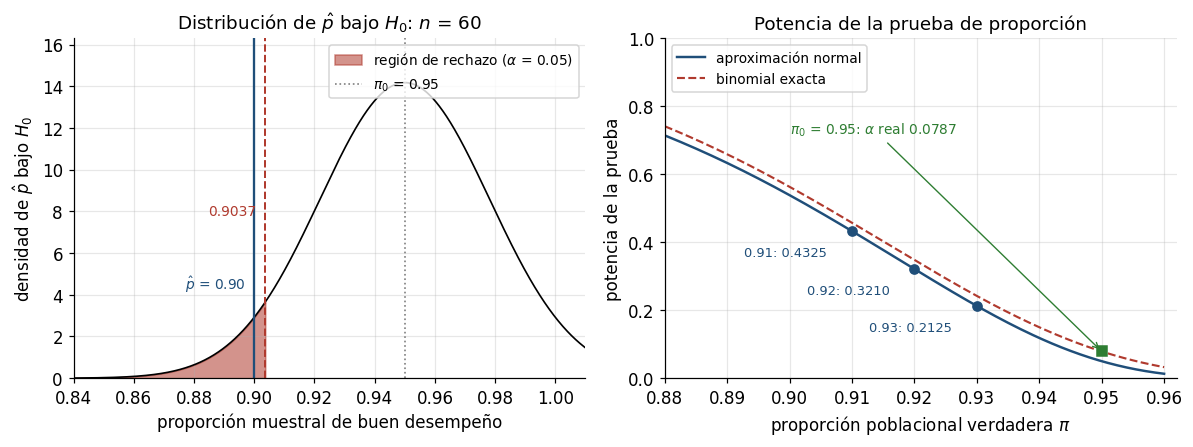

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

# panel izquierdo: distribucion de p_hat bajo H0
malla = np.linspace(0.84, 1.01, 1000)
dens = np.exp(-0.5 * ((malla - pi0) / se0) ** 2) / (se0 * math.sqrt(2 * math.pi))
altura = dens.max()

axs[0].plot(malla, dens, color="black", linewidth=1.1)
axs[0].fill_between(malla, 0, dens, where=malla <= umbral, color=ROJO, alpha=0.55,
                    label=r"región de rechazo ($\alpha$ = 0.05)")
axs[0].axvline(umbral, color=ROJO, linewidth=1.3, linestyle="--")
axs[0].text(umbral - 0.003, altura * 0.55, f"{umbral:.4f}", color=ROJO, fontsize=9, ha="right")
axs[0].axvline(p_hat, color=AZUL, linewidth=1.5)
axs[0].text(p_hat - 0.003, altura * 0.30, r"$\hat{p}$ = 0.90", color=AZUL, fontsize=9, ha="right")
axs[0].axvline(pi0, color=GRIS, linewidth=1.1, linestyle=":", label=r"$\pi_0$ = 0.95")
axs[0].set_xlim(0.84, 1.01)
axs[0].set_ylim(0, altura * 1.15)
axs[0].set_xlabel("proporción muestral de buen desempeño")
axs[0].set_ylabel("densidad de $\\hat{p}$ bajo $H_0$")
axs[0].set_title(r"Distribución de $\hat{p}$ bajo $H_0$: $n$ = 60")
axs[0].legend(fontsize=9, loc="upper right")

# panel derecho: potencia contra pi, aproximacion y exacta
pi_grilla = np.linspace(0.88, 0.96, 161)
se_grilla = np.sqrt(pi_grilla * (1 - pi_grilla) / n_pu)
pot_norm = Phi_vec((umbral - pi_grilla) / se_grilla)
pot_exacta = np.array([binom_cdf(x_umbral, n_pu, p_) for p_ in pi_grilla])

axs[1].plot(pi_grilla, pot_norm, color=AZUL, linewidth=1.6, label="aproximación normal")
axs[1].plot(pi_grilla, pot_exacta, color=ROJO, linewidth=1.4, linestyle="--",
            label="binomial exacta")
for pi in (0.93, 0.92, 0.91):
    se1 = math.sqrt(pi * (1 - pi) / n_pu)
    pot = Phi((umbral - pi) / se1)
    axs[1].plot(pi, pot, "o", color=AZUL, markersize=6, zorder=5)
    axs[1].text(pi - 0.004, pot - 0.075, f"{pi}: {pot:.4f}", fontsize=8.5, color=AZUL,
                ha="right")
axs[1].plot(pi0, binom_cdf(x_umbral, n_pu, pi0), "s", color=VERDE, markersize=7, zorder=5)
axs[1].annotate(r"$\pi_0$ = 0.95: $\alpha$ real 0.0787", xy=(pi0, binom_cdf(x_umbral, n_pu, pi0)),
                xytext=(0.900, 0.72), fontsize=9, color=VERDE,
                arrowprops=dict(arrowstyle="->", linewidth=0.9, color=VERDE))
axs[1].set_xlim(0.88, 0.962)
axs[1].set_ylim(0, 1.0)
axs[1].set_xlabel(r"proporción poblacional verdadera $\pi$")
axs[1].set_ylabel("potencia de la prueba")
axs[1].set_title("Potencia de la prueba de proporción")
axs[1].legend(fontsize=9, loc="upper left")

plt.tight_layout()
plt.show()


## 5. Accidentes de trabajo: prueba unilateral con nivel 6%

Un informe de una empresa de seguros indicó que en la industria metalúrgica el 10% de los operarios
ha tenido más de un accidente de trabajo. Un grupo de asesoría considera ese porcentaje muy elevado y
decide investigar la afirmación. Una muestra de $n = 200$ operarios mostró que $x = 13$ habían tenido
más de un accidente. Nivel de significación $\alpha = 0.06$.

### a) Hipótesis

$$H_0: \pi = 0.10 \qquad \text{vs} \qquad H_1: \pi < 0.10$$

$H_0$ reproduce la cifra publicada por la empresa de seguros; $H_1$ es la sospecha del grupo de
asesoría, de que el porcentaje real es menor. La alternativa es unilateral izquierda: solo interesa
constatar que la cifra real queda por debajo del 10%, no cualquier desvío.

### b) Estadístico de prueba y distribución muestral

$$Z = \frac{\hat p - \pi_0}{\sqrt{\pi_0(1-\pi_0)/n}} = \frac{\hat p - 0.10}{\sqrt{0.10 \times 0.90 / 200}}$$

Bajo $H_0$, $Z \sim N(0,1)$ y $\hat p \sim N(0.10,\ 0.021213^2)$, con error estándar

$$\sqrt{\frac{0.10 \times 0.90}{200}} = \sqrt{0.00045} = 0.021213$$

Las condiciones de aproximación se cumplen holgadamente: $n\pi_0 = 20 \ge 5$ y
$n(1-\pi_0) = 180 \ge 5$.

### c) Regla de decisión para $n = 200$

Con $\alpha = 0.06$ y cola izquierda, el cuantil de referencia es $z_{0.06} = 1.554774$:

$$\text{rechazar } H_0 \ \text{ si } \ z < -1.554774$$

En la escala de la proporción:

$$\hat p < 0.10 - 1.554774 \times 0.021213 = 0.067018$$

Como $\hat p$ es un múltiplo de $1/200$, la regla equivale a $X \le 13$ operarios con más de un
accidente.

### d) Decisión

$$\hat p = \frac{13}{200} = 0.065, \qquad z = \frac{0.065 - 0.10}{0.021213} = -1.6499 \ < \ -1.554774$$

$$p = P(Z < -1.6499) = 0.049480 \ < \ 0.06$$

Se rechaza $H_0$: al nivel del 6%, la proporción de operarios con más de un accidente es
significativamente menor al 10% publicado. La muestra queda justo en la frontera de la regla
(X = 13 satisface $\hat p < 0.067018$ por poco), y el valor p de 0.0495 apenas supera el umbral: la
conclusión es correcta para el método elegido, pero con poca holgura.

### e) Potencia si el porcentaje real fuera 8%

Con $\pi = 0.08$, el error estándar bajo la alternativa es $\sqrt{0.08 \times 0.92/200} =
0.019183$ y el umbral fijo se estandariza así:

$$\text{potencia} = P(\hat p < 0.067018 \mid \pi = 0.08) = \Phi\!\left(\frac{0.067018 - 0.08}{0.019183}\right) = \Phi(-0.6767) = 0.2493$$

Con la regla en enteros ($X \le 13$), la binomial exacta da 0.2643. En cualquiera de los dos
cálculos: si el porcentaje real fuera 8%, esta prueba lo detectaría —concluyendo que es menor al
10%— solo una de cada cuatro veces. El resto de las veces, la muestra quedaría dentro de la región
de no rechazo y la cifra publicada seguiría en pie, pese a ser falsa. Con $n = 200$ el error tipo II
domina el comportamiento de la prueba cerca de la hipótesis.

In [12]:
n_op, x_op = 200, 13
p0, alpha = 0.10, 0.06

p_hat = x_op / n_op
se0 = math.sqrt(p0 * (1 - p0) / n_op)
z_crit = Z[alpha]
z = (p_hat - p0) / se0
umbral = p0 - z_crit * se0
x_umbral = math.floor(umbral * n_op)
p_valor = Phi(z)

print(f"H0: pi = {p0:.2f} vs H1: pi < {p0:.2f}   |   alpha = {alpha}, n = {n_op}, x = {x_op}")
print(f"condicion normal: n*pi0 = {n_op * p0:.0f} >= 5, n*(1-pi0) = {n_op * (1 - p0):.0f} >= 5")
print(f"p_hat = {x_op}/{n_op} = {p_hat:.4f}, error estandar bajo H0 ="
      f" sqrt({p0:.2f} x {1 - p0}/{n_op}) = {se0:.6f}")
print()
print(f"c) regla estandarizada: rechazar si z < -{z_crit:.6f}")
print(f"   escala de p_hat: p_hat < {p0} - {z_crit:.6f} x {se0:.6f} = {umbral:.6f}")
print(f"   equivale a X <= {x_umbral} (p_hat es multiplo de 1/{n_op})")
print()
print(f"d) z = ({p_hat:.4f} - {p0})/{se0:.6f} = {z:.4f}"
      f"   -> {'rechazar H0' if z < -z_crit else 'no rechazar H0'}")
print(f"   valor p = P(Z < {z:.4f}) = {p_valor:.6f}")
print()

p1 = 0.08
se1 = math.sqrt(p1 * (1 - p1) / n_op)
z1 = (umbral - p1) / se1
pot_norm = Phi(z1)
pot_exacta = binom_cdf(x_umbral, n_op, p1)
print(f"e) si pi = {p1}: error estandar = sqrt({p1} x {1 - p1}/{n_op}) = {se1:.6f}")
print(f"   z = ({umbral:.6f} - {p1})/{se1:.6f} = {z1:.4f} -> potencia = Phi({z1:.4f}) = {pot_norm:.4f}")
print(f"   binomial exacta P(X <= {x_umbral} | pi = {p1}) = {pot_exacta:.4f}")
print(f"   deteccion: 1 de cada {1 / pot_norm:.1f} muestras (normal) o {1 / pot_exacta:.1f} (exacta)")


H0: pi = 0.10 vs H1: pi < 0.10   |   alpha = 0.06, n = 200, x = 13
condicion normal: n*pi0 = 20 >= 5, n*(1-pi0) = 180 >= 5
p_hat = 13/200 = 0.0650, error estandar bajo H0 = sqrt(0.10 x 0.9/200) = 0.021213

c) regla estandarizada: rechazar si z < -1.554774
   escala de p_hat: p_hat < 0.1 - 1.554774 x 0.021213 = 0.067018
   equivale a X <= 13 (p_hat es multiplo de 1/200)

d) z = (0.0650 - 0.1)/0.021213 = -1.6499   -> rechazar H0
   valor p = P(Z < -1.6499) = 0.049480

e) si pi = 0.08: error estandar = sqrt(0.08 x 0.92/200) = 0.019183
   z = (0.067018 - 0.08)/0.019183 = -0.6767 -> potencia = Phi(-0.6767) = 0.2493
   binomial exacta P(X <= 13 | pi = 0.08) = 0.2643
   deteccion: 1 de cada 4.0 muestras (normal) o 3.8 (exacta)


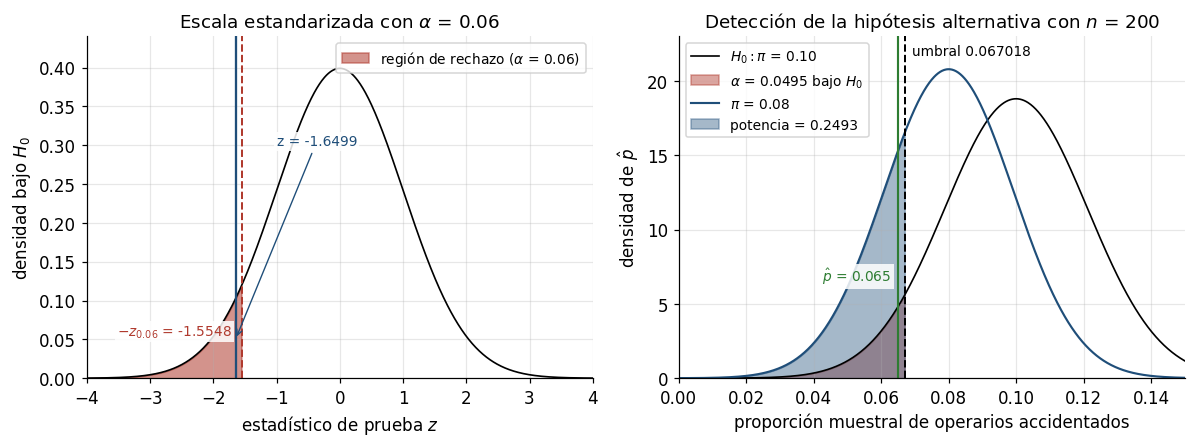

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

# panel izquierdo: escala estandarizada
malla = np.linspace(-4, 4, 1000)
dens = np.exp(-0.5 * malla**2) / math.sqrt(2 * math.pi)

axs[0].plot(malla, dens, color="black", linewidth=1.1)
axs[0].fill_between(malla, 0, dens, where=malla <= -z_crit, color=ROJO, alpha=0.55,
                    label=r"región de rechazo ($\alpha$ = 0.06)")
axs[0].axvline(-z_crit, color=ROJO, linewidth=1.3, linestyle="--")
axs[0].text(-z_crit - 0.15, 0.055, r"$-z_{0.06}$ = -1.5548", color=ROJO, fontsize=9, ha="right",
            bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=1.5))
axs[0].axvline(z, color=AZUL, linewidth=1.5)
axs[0].annotate(f"z = {z:.4f}", xy=(z, 0.05), xytext=(-1.0, 0.30), color=AZUL, fontsize=9,
                bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=1.5),
                arrowprops=dict(arrowstyle="->", linewidth=0.9, color=AZUL))
axs[0].set_xlim(-4, 4)
axs[0].set_ylim(0, 0.44)
axs[0].set_xlabel(r"estadístico de prueba $z$")
axs[0].set_ylabel("densidad bajo $H_0$")
axs[0].set_title(r"Escala estandarizada con $\alpha$ = 0.06")
axs[0].legend(fontsize=9, loc="upper right")

# panel derecho: distribuciones bajo H0 y bajo pi = 0.08
malla2 = np.linspace(0.0, 0.15, 1000)
se1 = math.sqrt(0.08 * 0.92 / n_op)
dens0 = np.exp(-0.5 * ((malla2 - p0) / se0) ** 2) / (se0 * math.sqrt(2 * math.pi))
dens1 = np.exp(-0.5 * ((malla2 - 0.08) / se1) ** 2) / (se1 * math.sqrt(2 * math.pi))

axs[1].plot(malla2, dens0, color="black", linewidth=1.1, label=r"$H_0: \pi$ = 0.10")
axs[1].fill_between(malla2, 0, dens0, where=malla2 <= umbral, color=ROJO, alpha=0.45,
                    label=r"$\alpha$ = 0.0495 bajo $H_0$")
axs[1].plot(malla2, dens1, color=AZUL, linewidth=1.4, label=r"$\pi$ = 0.08")
axs[1].fill_between(malla2, 0, dens1, where=malla2 <= umbral, color=AZUL, alpha=0.4,
                    label=r"potencia = 0.2493")
axs[1].axvline(umbral, color="black", linewidth=1.3, linestyle="--")
axs[1].text(umbral + 0.002, 21.7, f"umbral {umbral:.6f}", fontsize=9)
axs[1].axvline(p_hat, color=VERDE, linewidth=1.4)
axs[1].text(p_hat - 0.002, 6.5, r"$\hat{p}$ = 0.065", fontsize=9, color=VERDE, ha="right",
            bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=1.5))
axs[1].set_xlim(0.0, 0.15)
axs[1].set_ylim(0, 23)
axs[1].set_xlabel("proporción muestral de operarios accidentados")
axs[1].set_ylabel("densidad de $\\hat{p}$")
axs[1].set_title("Detección de la hipótesis alternativa con $n$ = 200")
axs[1].legend(fontsize=9, loc="upper left")

plt.tight_layout()
plt.show()


## Notas de validación

- Los cinco cuantiles de la tabla del marco teórico se verifican con la función error complementaria:
  las colas resultantes son 0.050000, 0.060000, 0.025000, 0.010000 y 0.005000, exactamente las
  probabilidades de cola para las que están tabulados. Todo el notebook usa esos valores, con la clave
  en la probabilidad de la cola de rechazo para no confundir unilateral con bilateral.
- Resumen de resultados: sección 1, $z = 7.3951$, umbral 152.2242 u/h, $p = 7.07 \times 10^{-14}$,
  se rechaza; sección 2, umbral 21.5015 g, $z = 2.5195$, $p = 0.005876$, $\beta = 0.2925$ y
  potencia 0.7075 con $\mu = 22$, y $\alpha = 0.0225$ si el umbral sube a 21.83 g; sección 3, rango
  de control $[4.1617, 5.0383]$ cm, $z = -1.1180$, $p = 0.2636$, no se rechaza, con
  $\beta = 0.8545/0.9268/0.9500/0.9268/0.8545$; sección 4, $z = -1.7770$, $p = 0.037780$, se
  rechaza, potencias 0.2125, 0.3210 y 0.4325; sección 5, $z = -1.6499$, $p = 0.049480$, se rechaza,
  potencia 0.2493 con $\pi = 0.08$.
- En la sección 3, $\beta(4.60) = 0.95$ no es un valor calculado sino una identidad: con $H_0$
  verdadera, la región de no rechazo contiene exactamente la probabilidad $1 - \alpha$. La curva
  $\beta(\mu)$ alcanza su máximo ahí y baja en los dos sentidos, como corresponde a una prueba
  bilateral.
- La simulación Monte Carlo de la sección 2 usa 100.000 muestras con semilla 11. Las desviaciones
  entre el valor simulado y el calculado se mantienen dentro de tres errores muestrales
  $\sqrt{p(1-p)/M}$ (0.0007 para $\alpha$ y 0.0014 para $\beta$), que es todo lo que permite
  esperar el muestreo finito.
- No rechazar $H_0$ no es aceptarla: en la sección 3, $p = 0.2636$ significa que la muestra es
  compatible con $\mu = 4.6$, no que la media sea 4.6. Toda la lectura de las pruebas se apoya en la
  evidencia en contra de $H_0$, nunca en una verificación de su verdad.
- En la sección 4 la condición $n(1-\pi_0) \ge 5$ queda incumplida ($60 \times 0.05 = 3$), y eso se
  refleja en la comparación con la binomial exacta: el tamaño real de la regla $X \le 54$ es 0.0787
  frente al 0.0378 de la aproximación normal (0.0693 con corrección de continuidad). La potencia
  exacta supera en unos dos puntos a la normal en los tres valores ensayados. La decisión del
  ejercicio se toma con el estadístico estandarizado que pide el enunciado; el reparo queda explícito
  porque la conclusión al 5% cambia con la prueba exacta.
- En la sección 5 las condiciones de aproximación sí se cumplen (20 y 180), y la binomial exacta
  confirma el rechazo: $P(X \le 13 \mid \pi = 0.10) = 0.0566 \le 0.06$. La potencia exacta con
  $\pi = 0.08$ (0.2643) queda cercana a la normal (0.2493); la diferencia se debe a que la regla en
  enteros admite $X = 13$ completo mientras la normal sin corrección lo trata como continuo.
- Los errores tipo II de las secciones 2 a 5 se calculan siempre estandarizando el umbral de
  decisión bajo la media o la proporción alternativa, nunca restando probabilidades de las
  distribuciones bajo $H_0$: $\beta$ vive en la distribución de $H_1$ y usar la nula para calcularlo
  es el error de procedimiento más común en estos ejercicios.

Referencias: Walpole, R. - Probabilidad y estadística para ingeniería y ciencias. Casella, G. y
Berger, R. - Statistical Inference. Hogg, R. y Craig, J. - Introducción a la teoría de la
probabilidad y la estadística. Mood, A., Graybill, F. y Boes, D. - Introducción a la teoría de la
estadística.